---
authors:
  - name: Emma Pidduck
    url: https://www.linkedin.com/in/emmapidduck/
---

# Day 28 · Senses: Feeling — How many layers, Beethoven?

<img src="assets/ECMWF_Core_Logo_RGB.png" width="170" alt="ECMWF logo">

### #30DayMapChallenge 2026 · ECMWF IFS 9 km open data · Map by Emma Pidduck

> ⚠️ **Just for fun — not an official ECMWF product.** Claude (Anthropic) helped build
> these notebooks. They are **not** official ECMWF notebooks and are **not** supported by
> ECMWF — a personal [#30DayMapChallenge](https://30daymapchallenge.com/) experiment.

> 🤖 **The Beethoven photos are AI-generated.** They were made in Canva from the prompts listed below,
> describing the Beethoven statue on Münsterplatz in Bonn. They are not photographs of the real statue.
> The *map and every number* come from the ECMWF forecast; the AI only drew the knitwear.

It was **biting** in Germany on Saturday 28 November 2026: a little below zero, with a wind that made it
feel much colder. Thermometers tell you the air temperature; your face feels the **wind chill**.

So we asked Bonn's most famous resident to dress for it. For every three hours of the ECMWF forecast,
Beethoven puts on as many layers as the feels-like temperature demands: a scarf, then a bobble hat,
then mittens, then a second scarf over his nose. Next to him, the same feels-like temperature across all of Germany.

Self-contained: method, code, output, data licence and tools in one place, runnable on any laptop with `pip`.

![How many layers, Beethoven?](day28_feeling_beethoven.png)


## Method

- Fetch **2 m temperature** (`2t`) and **10 m wind** (`10u`, `10v`) from the ECMWF IFS forecast at **9 km**
  (0.1°, open data), every 3 hours through the day.
- Compute the **wind chill** with the formula used by Environment Canada and the US National Weather Service
  (JAG/TI, 2001), where $T$ is the air temperature in °C and $V$ the 10 m wind speed in km/h:

  $$T_{wc} = 13.12 + 0.6215\,T - 11.37\,V^{0.16} + 0.3965\,T\,V^{0.16}$$

  It is defined for $T \le 10$ °C and $V \ge 4.8$ km/h; elsewhere the feels-like is just the air temperature.
- Dress Beethoven by the **feels-like in Bonn** (nearest 9 km grid point to Münsterplatz):

  | Feels-like | Layer |
  |---|---|
  | below 5 °C | scarf |
  | below 0 °C | bobble hat |
  | below −3 °C | mittens |
  | below −6 °C | scarf over the nose |
  | below −9 °C | icicle on the nose |

  The big portrait is the **coldest hour of the day**; the strip below follows him through the day.
- The map shows the feels-like across **Germany** at that same hour, clipped to the national border, with
  the 10 m wind as arrows.


## Data

| Dataset | What is used | Licence |
|---|---|---|
| [ECMWF Open Data](https://www.ecmwf.int/en/forecasts/datasets/open-data) — IFS HRES, 0.1° (9 km) | 2 m temperature `2t`, 10 m wind `10u` `10v`; run 12 UTC 27 Nov 2026, +12 h to +36 h every 3 h | CC-BY-4.0 |
| [Natural Earth](https://www.naturalearthdata.com) 1:10m | country borders, the German border used as a clip, rivers | public domain |
| Beethoven images, generated in [Canva](https://www.canva.com) (AI image generation), 28 Nov 2026 | four images: bare statue, 2, 3 and 4 layers (`assets/beethoven/`) | AI-generated, see below |

No account needed for the forecast data. Note that the 9 km open data is published about a day after the run,
so "today" comes from yesterday's 12 UTC run.

## Licence & attribution

Access to ECMWF Open Data is governed by the **Creative Commons CC-BY-4.0** licence and the
associated [Terms of Use](https://apps.ecmwf.int/datasets/licences/general/).

> In applying this licence, ECMWF does not waive the privileges and immunities granted to it
> by virtue of its status as an intergovernmental organisation.

When you share a map made from this data, attribute it:
`© ECMWF · Source: www.ecmwf.int · Licence: CC-BY-4.0 and ECMWF Terms of Use`

Borders and rivers: [Natural Earth](https://www.naturalearthdata.com) (public domain).

**AI-generated images.** The Beethoven pictures were generated with Canva's AI image generator and are used
here under [Canva's terms](https://www.canva.com/policies/ai-product-terms/). They are illustrations, not
photographs, and not a record of the real statue. Say so whenever you share the poster.


## How the Beethoven images were made

One base image was generated from a text prompt. Each dressed version was then generated **with the base image as a reference**, so the statue, pose and light stay the same and only the knitwear changes. Aspect ratio 4:5. Generative models are not deterministic, so running the same prompts again gives similar but not identical images; the images used for the poster are saved in `assets/beethoven/`.

| Image | Canva media id | Reference | Prompt |
|---|---|---|---|
| 0 layers (base) | `MAHcOXGTvTA` | none | A more hyper-realistic representation of Beethoven: the bronze Beethoven statue on Münsterplatz in Bonn, photorealistic photograph, green-brown patina, cold grey November morning, frosty, head and shoulders down to the waist, plain sky behind, no people, no text. |
| 2 layers | `MAHcOTJDhN4` | `MAHcOXGTvTA` | Same bronze Beethoven statue, same pose, framing and lighting, now wearing a real red-and-white striped knitted wool scarf around the neck and a matching red knitted bobble hat with a cream pompom, photorealistic, frosty November, plain sky, no text. |
| 3 layers | `MAHcOQEoqpU` | `MAHcOXGTvTA` | Same bronze Beethoven statue, same pose, framing and lighting, now wearing a real red-and-white striped knitted wool scarf around the neck, a matching red knitted bobble hat with a cream pompom, and chunky mustard-yellow knitted mittens on both hands raised in front of the chest, photorealistic, frosty November, plain sky, no text. |
| 4 layers | `MAHcOUWnpNI` | `MAHcOXGTvTA` | Same bronze Beethoven statue, same pose, framing and lighting, bundled up against biting wind: red knitted bobble hat with a cream pompom pulled down over the ears, a second thick navy-blue knitted scarf wrapped over the mouth and nose so only the eyes and frowning brows show, red-and-white striped scarf around the neck, chunky mustard-yellow knitted mittens, frost on the bronze, photorealistic, plain grey sky, no text. |

The first prompt starts with the request in Emma's own words, *"a more hyper-realistic representation of Beethoven"*. Today's weather only needed 2 to 4 layers; a day that needs 1 or 5 falls back to the nearest image (the code prints a note when it does).

## Tools

| Tool | Role |
|---|---|
| ECMWF Open Data `.index` files + HTTP range requests | fetch just the three fields needed from the 9 km files |
| [`xarray`](https://xarray.dev) + [`cfgrib`](https://github.com/ecmwf/cfgrib) | read the GRIB, with coordinates from the file |
| `numpy`, `scipy` | wind chill, light smoothing |
| [`cartopy`](https://scitools.org.uk/cartopy/) | the map of Germany, Natural Earth borders and rivers |
| `matplotlib` | the poster |
| [Fredoka](https://fonts.google.com/specimen/Fredoka) | the font (SIL Open Font Licence, in `assets/fonts/`) |
| [Canva](https://www.canva.com) AI image generation | the four Beethoven images (done once, not part of the code) |

```bash
pip install xarray cfgrib eccodes numpy scipy cartopy matplotlib
```

One gotcha: ECMWF open-data grids start at **180° E**, not at Greenwich, so always take longitudes from the
file rather than building them yourself.

**Learn more:** [ECMWF Open Data](https://www.ecmwf.int/en/forecasts/datasets/open-data) · [wind chill (Environment Canada)](https://www.canada.ca/en/environment-climate-change/services/weather-health/wind-chill-cold-weather/wind-chill-index.html) · [IFS documentation](https://www.ecmwf.int/en/publications/ifs-documentation)


In [1]:
# Run once if needed (uncomment):
#!pip install xarray cfgrib eccodes numpy scipy cartopy matplotlib

## Settings

In [2]:
RUN = "2026112712"      # IFS run YYYYMMDDHH (9 km open data appears about a day later)
S0, S1 = 12, 36        # forecast steps covering the local day
MAPH = None            # UTC hour for the big portrait and the map; None = the coldest hour in Bonn

## Retrieve

Only `2t`, `10u` and `10v` are taken from each 9 km file, by byte range from the `.index`.

In [3]:
import os, json, time, urllib.request
BASE = f"https://data.ecmwf.int/forecasts/{RUN[:8]}/{RUN[8:]}z/ifs/0p1/oper/{RUN}0000"

def get(req):
    for i in range(8):
        try:
            return urllib.request.urlopen(req, timeout=120).read()
        except Exception:
            time.sleep(2 * (i + 1))
    raise RuntimeError(req)

os.makedirs("data", exist_ok=True)
PATH = f"data/bonn_{RUN}_0p1.grib2"
if os.path.exists(PATH):
    print("already have", PATH)
else:
    with open(PATH, "wb") as out:
        for s in range(S0, S1 + 1, 3):
            u = f"{BASE}-{s}h-oper-fc-sfc"
            recs = [json.loads(l) for l in get(f"{u}.index").decode().splitlines()]
            for r in recs:
                if r["param"] in ("2t", "10u", "10v"):
                    rng = f"bytes={r['_offset']}-{r['_offset'] + r['_length'] - 1}"
                    out.write(get(urllib.request.Request(f"{u}.grib2", headers={"Range": rng})))
            print("step", s)

already have data/bonn_2026112712_0p1.grib2


## Read and compute the wind chill

In [4]:
import os, sys, datetime as dt
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.image as mpimg
from matplotlib import font_manager as fm
from matplotlib.patches import Ellipse, Polygon, Circle, FancyBboxPatch, PathPatch
from matplotlib.path import Path
import matplotlib.patheffects as pe
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader
from scipy.ndimage import gaussian_filter

fm.fontManager.addfont("assets/fonts/Fredoka.ttf"); FONT = "Fredoka"
plt.rcParams["font.family"] = FONT
BONN = (50.7374, 7.0982)
BOX = (47.0, 55.3, 5.5, 15.5)            # S N W E: Germany

# data
def var(short):
    ds = xr.open_dataset(f"data/bonn_{RUN}_0p1.grib2", engine="cfgrib",
                         backend_kwargs={"indexpath": "", "filter_by_keys": {"shortName": short}})
    da = ds[list(ds.data_vars)[0]]
    da = da.assign_coords(longitude=((da.longitude + 180) % 360) - 180).sortby("longitude")
    return da.sel(latitude=slice(BOX[1] + 0.3, BOX[0] - 0.3), longitude=slice(BOX[2] - 0.3, BOX[3] + 0.3))
T = var("2t") - 273.15
U, V = var("10u"), var("10v")
WKMH = np.hypot(U, V) * 3.6
def windchill(t, v):
    """Environment Canada / US NWS wind chill (JAG/TI 2001). Defined for T <= 10 C and wind >= 4.8 km/h."""
    wc = 13.12 + 0.6215 * t - 11.37 * v ** 0.16 + 0.3965 * t * v ** 0.16
    return xr.where((t <= 10) & (v >= 4.8), wc, t)
WC = windchill(T, WKMH)
valid = [dt.datetime.utcfromtimestamp(int(x) / 1e9) for x in WC.valid_time.values.astype("datetime64[ns]").astype(int)]
at = lambda da, k: float(da.isel(step=k).sel(latitude=BONN[0], longitude=BONN[1], method="nearest"))
local = lambda d: d + dt.timedelta(hours=1)          # CET in November
series = [(valid[k], at(T, k), at(WC, k), at(WKMH, k)) for k in range(len(valid))]
for d, t, w, v in series:
    print(f"{local(d):%a %H:%M} CET  T {t:5.1f}  wind {v:4.1f} km/h  feels {w:5.1f}")

# layer rules, by feels-like temperature
RULES = [(5, "scarf"), (0, "bobble hat"), (-3, "mittens"), (-6, "scarf over the nose"), (-9, "icicle on the nose")]
def layers(wc): return [name for thr, name in RULES if wc <= thr]

Sat 01:00 CET  T  -3.1  wind  7.9 km/h  feels  -6.4
Sat 04:00 CET  T  -3.4  wind 10.9 km/h  feels  -7.6
Sat 07:00 CET  T  -3.3  wind 10.7 km/h  feels  -7.5
Sat 10:00 CET  T  -1.0  wind  9.8 km/h  feels  -4.4
Sat 13:00 CET  T   2.5  wind 16.1 km/h  feels  -1.6
Sat 16:00 CET  T   1.8  wind 14.1 km/h  feels  -2.0
Sat 19:00 CET  T   0.4  wind 17.7 km/h  feels  -4.4
Sat 22:00 CET  T   0.9  wind 17.9 km/h  feels  -3.8
Sun 01:00 CET  T   0.4  wind 16.9 km/h  feels  -4.2


/var/folders/vb/d9d9x5_d2j961cwy8cw4tqvh0000gn/T/ipykernel_95503/36290700.py:36: DeprecationWarning: datetime.datetime.utcfromtimestamp() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.fromtimestamp(timestamp, datetime.UTC).
  valid = [dt.datetime.utcfromtimestamp(int(x) / 1e9) for x in WC.valid_time.values.astype("datetime64[ns]").astype(int)]


## Beethoven's photos and the page

In [5]:
# the photos (AI-generated in Canva, see 'How the Beethoven images were made')
IMG = "assets/beethoven"
HAVE = sorted(int(f.split("_")[1]) for f in os.listdir(IMG) if f.startswith("beethoven_") and f.endswith("_layers.png"))
def photo(nlay):
    k = min(HAVE, key=lambda h: (abs(h - nlay), -h))          # nearest image we have; ties go to the warmer one
    if k != nlay:
        print(f"note: no image for {nlay} layers, using {k}")
    return mpimg.imread(os.path.join(IMG, f"beethoven_{k}_layers.png"))
def show(ax, nlay, frame="#14325c"):
    ax.imshow(photo(nlay)); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_edgecolor(frame); sp.set_linewidth(1.5)

findfont: Failed to find font weight normal for Fredoka, now using 300.


/var/folders/vb/d9d9x5_d2j961cwy8cw4tqvh0000gn/T/ipykernel_95503/735480588.py:46: DeprecationWarning: geos_to_path is deprecated and will be removed in a future release.  Use cartopy.mpl.path.shapely_to_path instead.
  clip = PathPatch(MPath.make_compound_path(*geos_to_path(proj.project_geometry(de, ccrs.PlateCarree()))),


findfont: Failed to find font weight bold for Fredoka, now using 300.


findfont: Failed to find font weight normal for Fredoka, now using 300.


findfont: Failed to find font weight bold for Fredoka, now using 300.


findfont: Failed to find font weight normal for Fredoka, now using 300.


... (4 outputs left out)

findfont: Failed to find font weight normal for Fredoka, now using 300.


findfont: Failed to find font weight bold for Fredoka, now using 300.


findfont: Failed to find font weight normal for Fredoka, now using 300.


findfont: Failed to find font weight normal for Fredoka, now using 300.


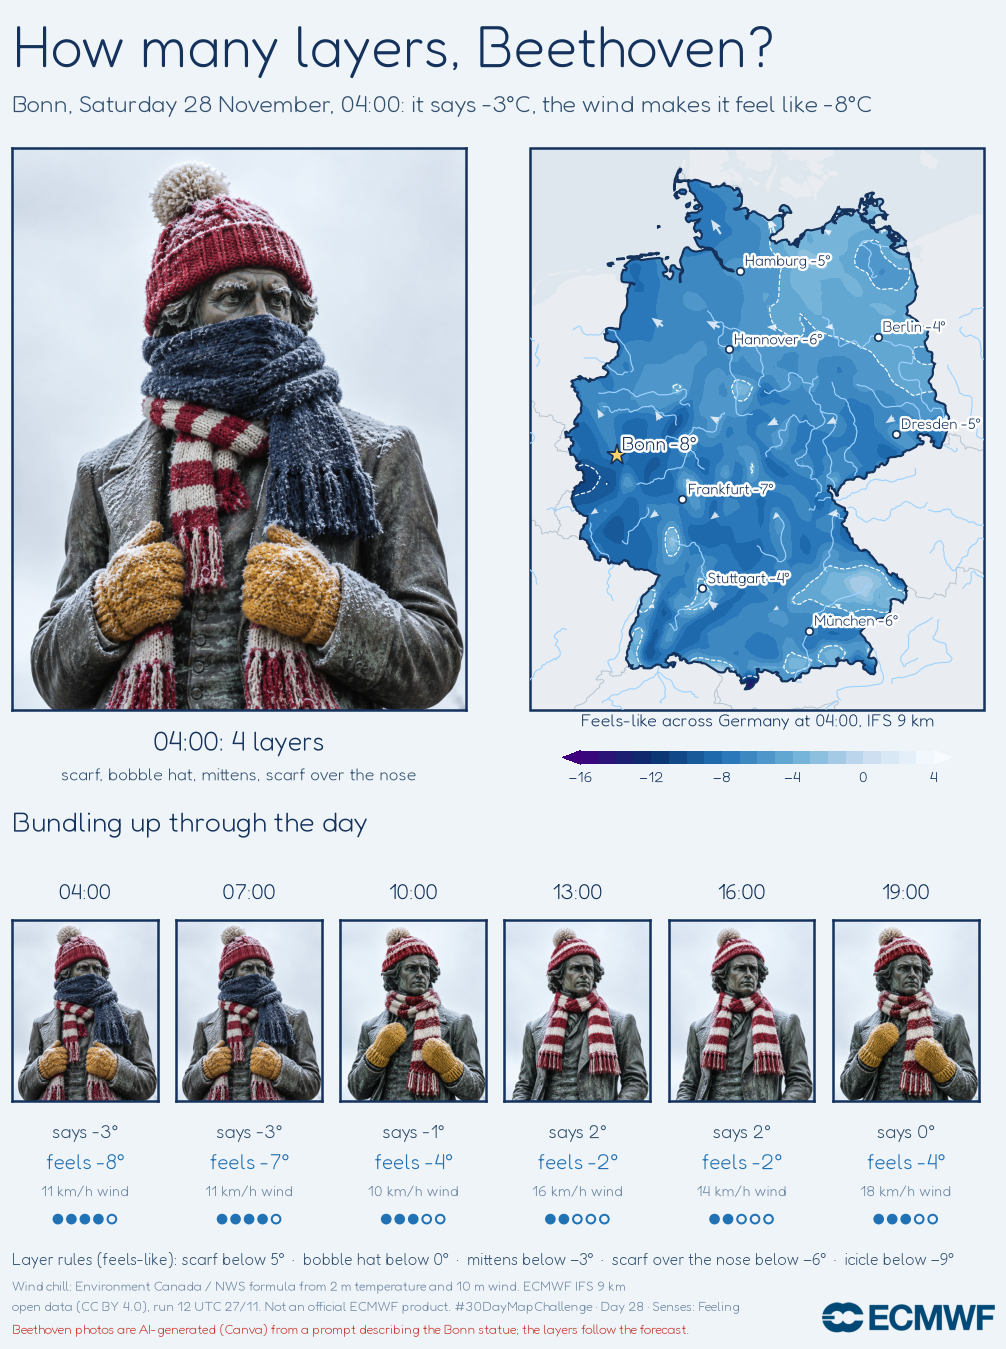

In [6]:
# page
BG = "#eef4f8"; DEEP = "#14325c"
fig = plt.figure(figsize=(9, 11.25), dpi=120, facecolor=BG)
day0 = local(valid[len(valid) // 2]).date()
inday = [k for k, d in enumerate(valid) if local(d).date() == day0]
k_map = [d.hour for d in valid].index(MAPH) if MAPH is not None else min(inday, key=lambda k: series[k][2])
dmap, tB, wB, vB = series[k_map]
fig.text(0.05, 0.952, "How many layers, Beethoven?", fontsize=34, fontweight="bold", color=DEEP)
fig.text(0.05, 0.918, f"Bonn, {local(dmap):%A %-d %B}, {local(dmap):%H:%M}: it says {tB:.0f}°C, the wind makes it feel like {wB:.0f}°C",
         fontsize=14.5, color="#33506f")

# two frames of the same size, side by side: Beethoven and the map of Germany
FW = 0.42                                         # frame width (figure fraction)
FH = FW * 9 / 11.25 / (1136 / 1408)               # same aspect as the photos
FY = 0.475
bx = fig.add_axes([0.05, FY, FW, FH])
show(bx, len(layers(wB)))
wear = layers(wB)
fig.text(0.05 + FW / 2, FY - 0.03, f"{local(dmap):%H:%M}: {len(wear)} layer{'s' if len(wear) != 1 else ''}", ha="center",
         fontsize=16, fontweight="bold", color=DEEP)
fig.text(0.05 + FW / 2, FY - 0.052, ", ".join(wear) if wear else "just his coat", ha="center", fontsize=10.5, color="#33506f")

proj = ccrs.LambertConformal(central_longitude=10.4, central_latitude=51.2, standard_parallels=(48, 54))
mx = fig.add_axes([0.53, FY, FW, FH], projection=proj)
de = [r for r in shpreader.Reader(shpreader.natural_earth("10m", "cultural", "admin_0_countries")).records()
      if r.attributes["ADMIN"] == "Germany"][0].geometry
x0, y0, x1, y1 = proj.project_geometry(de, ccrs.PlateCarree()).bounds
pad = 0.04 * (y1 - y0); y0 -= pad; y1 += pad
want = (x1 - x0 + 2 * pad) / (y1 - y0)
target = FW * 9 / (FH * 11.25)                    # make the map fill its frame exactly
cx_, half = (x0 + x1) / 2, (y1 - y0) * target / 2
mx.set_extent([cx_ - half, cx_ + half, y0, y1], crs=proj)
mx.set_facecolor("#dfe7ee")
mx.add_feature(cfeature.LAND.with_scale("10m"), facecolor="#e9edf1", edgecolor="none", zorder=0)
mx.add_feature(cfeature.BORDERS.with_scale("10m"), edgecolor="#b8c4d0", lw=0.6, zorder=0.5)
cmap = mcolors.LinearSegmentedColormap.from_list("bite", ["#f7fbff", "#c6dbef", "#6baed6", "#2171b5", "#08306b", "#3f007d"])
lv = np.arange(-16, 5, 1)
W0 = WC.isel(step=k_map)
cf = mx.contourf(W0.longitude, W0.latitude, gaussian_filter(W0.values, 0.6), levels=lv, cmap=cmap.reversed(),
                 extend="both", transform=ccrs.PlateCarree(), zorder=1)
cs = mx.contour(W0.longitude, W0.latitude, gaussian_filter(W0.values, 0.8), levels=[-10, -5, 0], colors="white",
                linewidths=0.7, transform=ccrs.PlateCarree(), zorder=2)
# show the wind chill only inside Germany
from cartopy.mpl.patch import geos_to_path
from matplotlib.path import Path as MPath
clip = PathPatch(MPath.make_compound_path(*geos_to_path(proj.project_geometry(de, ccrs.PlateCarree()))),
                 transform=mx.transData, facecolor="none", edgecolor=DEEP, lw=1.3, zorder=5)
mx.add_patch(clip)
cf.set_clip_path(clip); cs.set_clip_path(clip)
rivers = shpreader.natural_earth("10m", "physical", "rivers_europe")
rv = mx.add_geometries([r.geometry for r in shpreader.Reader(rivers).records()], ccrs.PlateCarree(), facecolor="none",
                       edgecolor="#9fd3ff", lw=0.7, zorder=3)
rv.set_clip_path(clip)
U0, V0 = U.isel(step=k_map), V.isel(step=k_map)
sl = (slice(None, None, 14), slice(None, None, 14))
q = mx.quiver(U0.longitude[sl[1]].values, U0.latitude[sl[0]].values, U0.values[sl], V0.values[sl], color="white",
              alpha=0.8, scale=130, width=0.005, headwidth=4, transform=ccrs.PlateCarree(), zorder=4)
q.set_clip_path(clip)
towns = [("Bonn", *BONN), ("Berlin", 52.52, 13.40), ("Hamburg", 53.55, 9.99), ("München", 48.14, 11.58),
         ("Frankfurt", 50.11, 8.68), ("Dresden", 51.05, 13.74), ("Stuttgart", 48.78, 9.18), ("Hannover", 52.37, 9.73)]
halo = [pe.withStroke(linewidth=3, foreground="white")]
for name, la, lo in towns:
    w = float(W0.sel(latitude=la, longitude=lo, method="nearest"))
    big = name == "Bonn"
    mx.plot(lo, la, marker="*" if big else "o", ms=13 if big else 4.5, color="#ffd166" if big else "white",
            mec=DEEP, mew=1, transform=ccrs.PlateCarree(), zorder=6)
    mx.text(lo + 0.12, la + 0.08, f"{name} {w:.0f}°", fontsize=11.5 if big else 9, fontweight="bold" if big else "normal",
            color=DEEP, transform=ccrs.PlateCarree(), zorder=7, path_effects=halo)
for sp in mx.spines.values(): sp.set_edgecolor(DEEP); sp.set_linewidth(1.5)
ca = fig.add_axes([0.53 + 0.03, FY - 0.04, FW - 0.06, 0.010])
cb = fig.colorbar(cf, cax=ca, orientation="horizontal", ticks=[-16, -12, -8, -4, 0, 4]); cb.outline.set_visible(False)
ca.tick_params(labelsize=9, length=0, colors=DEEP, pad=2)
fig.text(0.53 + FW / 2, FY - 0.012, f"Feels-like across Germany at {local(dmap):%H:%M}, IFS 9 km", ha="center",
         fontsize=10.5, color=DEEP)

# the day in Beethovens
picks = [k for k in inday if local(valid[k]).hour in (4, 7, 10, 13, 16, 19)]
n = len(picks)
fig.text(0.05, 0.385, "Bundling up through the day", fontsize=17, fontweight="bold", color=DEEP)
for i, k in enumerate(picks):
    d, t, w, v = series[k]
    x0 = 0.05 + i * 0.152; wd = 0.135
    a = fig.add_axes([x0, 0.185, wd, wd * 1.25 * 9 / 11.25])
    show(a, len(layers(w)))
    cx = x0 + wd / 2
    fig.text(cx, 0.335, f"{local(d):%H:%M}", ha="center", fontsize=13, fontweight="bold", color=DEEP)
    fig.text(cx, 0.158, f"says {t:.0f}°", ha="center", fontsize=11, color="#33506f")
    fig.text(cx, 0.135, f"feels {w:.0f}°", ha="center", fontsize=12.5, fontweight="bold", color="#2171b5" if w < 0 else DEEP)
    fig.text(cx, 0.115, f"{v:.0f} km/h wind", ha="center", fontsize=9, color="#6b84a0")
    dx = fig.add_axes([cx - 0.05, 0.088, 0.1, 0.02]); dx.set_xlim(-0.5, 4.5); dx.set_ylim(-1, 1); dx.axis("off")
    dx.set_aspect("equal")
    for j in range(len(RULES)):                       # one dot per possible layer, filled when worn
        dx.add_patch(Circle((j, 0), 0.32, fc="#2171b5" if j < len(layers(w)) else "none", ec="#2171b5", lw=1.2))
fig.text(0.05, 0.064, "Layer rules (feels-like): scarf below 5°  ·  bobble hat below 0°  ·  mittens below −3°  ·  "
         "scarf over the nose below −6°  ·  icicle below −9°", fontsize=9.5, color="#33506f")
fig.text(0.05, 0.045, f"Wind chill: Environment Canada / NWS formula from 2 m temperature and 10 m wind. ECMWF IFS 9 km",
         fontsize=8, color="#6b84a0")
fig.text(0.05, 0.030, f"open data (CC BY 4.0), run {RUN[8:]} UTC {RUN[6:8]}/{RUN[4:6]}. Not an official ECMWF product. "
         "#30DayMapChallenge · Day 28 · Senses: Feeling", fontsize=8, color="#6b84a0")
fig.text(0.05, 0.013, "Beethoven photos are AI-generated (Canva) from a prompt describing the Bonn statue; the layers follow the forecast.",
         fontsize=8, color="#c8352b")
lg = fig.add_axes([0.80, 0.005, 0.16, 0.04]); lg.imshow(mpimg.imread("assets/ECMWF_Core_Logo_RGB.png")); lg.axis("off")
out = "day28_feeling_beethoven.png"
fig.savefig(out, dpi=240, facecolor=BG); plt.show()

---
*Data © ECMWF, CC BY 4.0. Beethoven images AI-generated (Canva). Not an official ECMWF product.*